## **Autoencoder**
The following code will download MNIST dataset, and use *autoencoder* architecture to remove noise from images. I will train the model on noised images, and then I will see (plot) images before and after de-noising. In second part, I will focus on anomaly detection using the same architecture

![alt text](autoencoder.png)

In [52]:
import torch
from torch import nn
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
import matplotlib.pyplot as plt
import torch_directml

## Defining hyperparameters:
- `batch_size`
- `epochs`
- `noise_factor` - decides how intense the noise is on original picture
- `learning_rate`

In [53]:
BATCH_SIZE = 128
EPOCHS = 5
NOISE_FACTOR = 0.5
LEARNING_RATE = 1e-3

## Downloading and preparing data

In [54]:
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transforms.ToTensor())
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transforms.ToTensor())

train_dataloader = DataLoader(dataset=train_dataset, batch_size=BATCH_SIZE, shuffle=True, pin_memory=True)
test_dataloader = DataLoader(dataset=test_dataset, batch_size=6, shuffle=False, pin_memory=True)
# I set batch_size to 6 in test_dataloader, because I want to visualize just on 6 samples

In [55]:
train_dataset[0][0].shape

torch.Size([1, 28, 28])

## Defining linear and convolutional model

In this purely linear model, the bottleneck size is `encoding_dim // 4` - the output of last encoder layer == the input of first decoder layer

In [56]:
class DenoisingAutoencoder(nn.Module):
    def __init__(self, encoding_dim=128):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(28*28, encoding_dim),
            nn.ReLU(),
            nn.Linear(encoding_dim, encoding_dim//2),
            nn.ReLU(),
            nn.Linear(encoding_dim//2, encoding_dim//4)
        )
        self.decoder = nn.Sequential(
            nn.Linear(encoding_dim//4, encoding_dim//2),
            nn.ReLU(),
            nn.Linear(encoding_dim//2, encoding_dim),
            nn.ReLU(),
            nn.Linear(encoding_dim, 28*28),
            nn.Sigmoid()
        )

    def forward(self, X):
        encoded = self.encoder(X)
        decoded = self.decoder(encoded)
        return decoded

The case is different in this model, which involves colvolutional layers. The input is of a shape `[1, 28, 28]` -> `[color_channels, height, width]`. The math behind conv layers is about the simple formula for output size of each layer:
$$W_{out} = \lfloor \frac{W_{in} - K + 2P}{S} \rfloor + 1$$
where:

$W_{in}$ - input size (28 at the start)

$K$ - `kernel_size`

$P$ - `padding`

$S$ - `stride`

As a result, I've got [32, 4, 4] -> 512 features as an output -> it's the shape of the bottleneck

In [57]:
class DenoisingAutoencoderWithConvolutions(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 8, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(8, 16, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1),
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=0),
            nn.ReLU(),
            nn.ConvTranspose2d(16, 8, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(8, 1, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid()
        )

    def forward(self, X):
        encoded = self.encoder(X)
        decoded = self.decoder(encoded)
        return decoded
    

## Initializing model, device and overall environment

In [58]:
# model = DenoisingAutoencoder(encoding_dim=32)
model = DenoisingAutoencoderWithConvolutions()
device = torch_directml.device()
model.to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)



## Building a training loop

**Attention**: Both in training and evaluation of linear model, I had to use 

`images = images.view(images.size(0), -1).to(device)` 

because linear layer is 'blind' to geometry. It doesn't understand what is mesh of pixels, up, down or neighborhood. It just takes straight, one-dimensional sequence of values. That is why I had to use `.view()` method, to generate such sequence.

- `images.size(0)` - gets current batch size (e.g. 128)
- `-1` - shortcut in pytorch, which means 'calculate the rest of dimensions'. The image is 1x28x28 and PyTorch multiplies those values.

As a result, we get a tensor with a shape of `[128, 784]`

**Attention**: The convolutional layers work completely different - their strength is that they understand the geometry. They slide their filters around the mesh of an image. If I flattened the image before feeding it into convolution, I would have destroyed the valuable information and the model would give me an error

In [59]:
for epoch in range(EPOCHS):
    train_loss = 0.0
    for images, _ in train_dataloader:
        # images = images.view(images.size(0), -1).to(device)
        images = images.to(device)
        noisy_images = images + NOISE_FACTOR * torch.randn_like(images)
        noisy_images = torch.clamp(noisy_images, 0., 1.)

        outputs = model(noisy_images)
        loss = criterion(outputs, images)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss += loss.item()

    print(f'Epoch [{epoch+1}/{EPOCHS}], Loss: {train_loss/len(train_dataloader):.4f}')

Epoch [1/5], Loss: 0.1169
Epoch [2/5], Loss: 0.0598
Epoch [3/5], Loss: 0.0484
Epoch [4/5], Loss: 0.0423
Epoch [5/5], Loss: 0.0392


## Evaluation and visualization

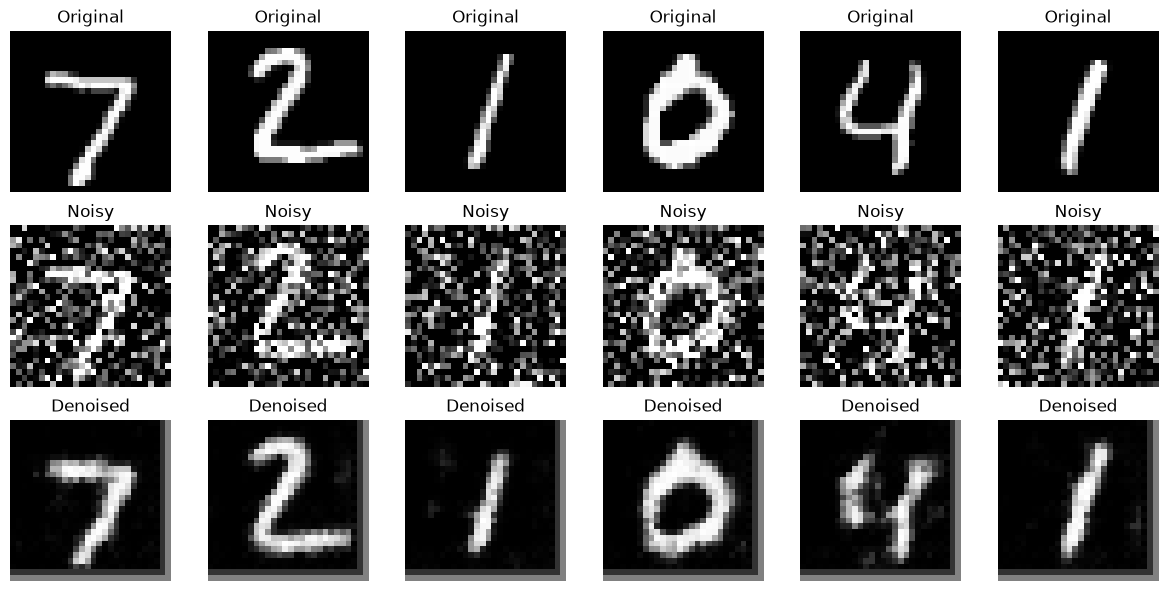

In [60]:
model.eval()
with torch.no_grad():
    dataiter = iter(test_dataloader)
    images, _ = next(dataiter)
    # images = images.view(images.size(0), -1).to(device)
    images = images.to(device)

    noisy_images = images + NOISE_FACTOR * torch.randn_like(images)
    noisy_images = torch.clamp(noisy_images, 0., 1.)

    outputs = model(noisy_images)

    images = images.cpu().numpy()
    noisy_images = noisy_images.cpu().numpy()
    outputs = outputs.cpu().numpy()

    fig, axes = plt.subplots(nrows=3, ncols=6, figsize=(12, 6))
    for i in range(6):
        axes[0, i].imshow(images[i].reshape(28, 28), cmap='gray')
        axes[0, i].axis('off')
        axes[0, i].set_title('Original')

        axes[1, i].imshow(noisy_images[i].reshape(28, 28), cmap='gray')
        axes[1, i].axis('off')
        axes[1, i].set_title('Noisy')

        axes[2, i].imshow(outputs[i].reshape(28, 28), cmap='gray')
        axes[2, i].axis('off')
        axes[2, i].set_title('Denoised')

    plt.tight_layout()
    plt.show()


## Visualizing the results

Lastly, I visualized the `latent space` - compresed representation of the data inside the bottleneck.

There are 2 main approaches to do that:
- build model with `encoding_dim = 2` so every image becomes a pair of coordinates (x, y) and we can plot it easily, but the network underfits
- keep big bottlenect, get those multi-dimensional vectors and then use outside algorithm to reduce this dimensionality (e.g. PCA or t-SNE).


I used the second option with `t-SNE`.

Computing t-SNE


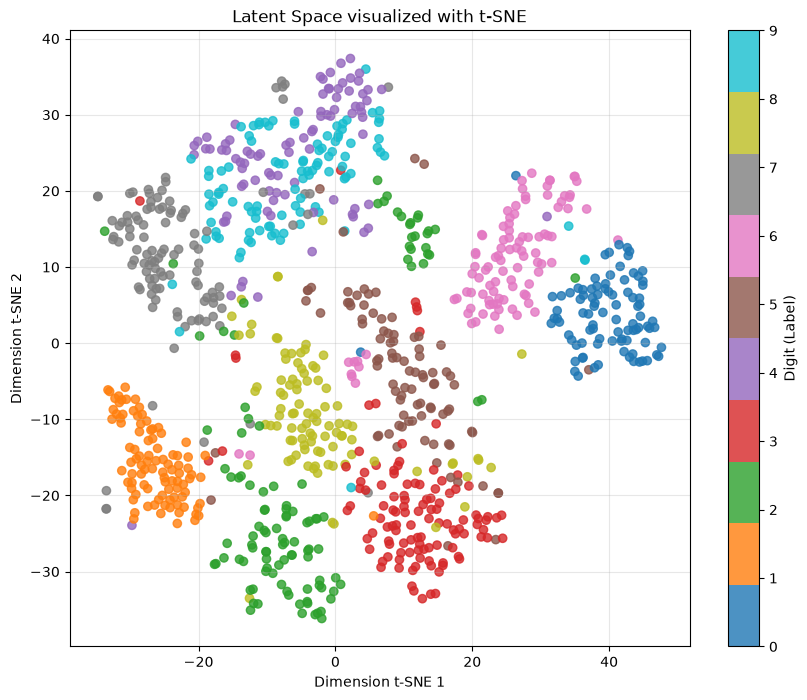

In [61]:
from sklearn.manifold import TSNE
import numpy as np

viz_dataloader = DataLoader(dataset=test_dataset, batch_size=1000, shuffle=True)

model.eval()
latent_vectors = []
labels_list = []

with torch.no_grad():
    images, labels = next(iter(viz_dataloader))
    images = images.to(device)
    
    # images = images.view(images.size(0), -1)

    latent = model.encoder(images)

    # Doesn't matter if it's a 2D tensor (linear model) or a 4D tensor (convolutional model),
    # we flatten the representation into flat vectors so that t-SNE can process them.
    latent = latent.view(latent.size(0), -1)
    
    latent_vectors = latent.cpu().numpy()
    labels_list = labels.numpy()

print("Computing t-SNE")
tsne = TSNE(n_components=2, random_state=42)
latent_2d = tsne.fit_transform(latent_vectors)

plt.figure(figsize=(10, 8))
scatter = plt.scatter(latent_2d[:, 0], latent_2d[:, 1], c=labels_list, cmap='tab10', alpha=0.8)
plt.colorbar(scatter, ticks=range(10), label='Digit (Label)')
plt.title('Latent Space visualized with t-SNE')
plt.xlabel('Dimension t-SNE 1')
plt.ylabel('Dimension t-SNE 2')
plt.grid(True, alpha=0.3)
plt.show()

## Overfitting and Underfitting

Of couse, as every different kind of model, autoencoders architectures may both underfit and overfit.

- Underfitting - bottleneck is too tight so model can't remember any details, so for every input model 'safely' guesses the mean shape - something like blurred 8, so it is somewhat similar to every digit
- Overfitting - model turns into lazy copy machine - identity function. It doesn't learn core shapes and features, but it abuses too wide bottlenect to just merge input pixels with output ones. The network stops removing noise. 

## Anomaly detection

In [62]:
BATCH_SIZE = 128
EPOCHS = 5
LEARNING_RATE = 1e-3
DEVICE = torch_directml.device(0)

## Data selection
I will train model using default, not deformed ones digits -> `train_ones`, `test_ones`. I just took indexes and then used them to create a subsets.

To evaluate, I will use nines digits as `anomalies` to the model -> `test_nines`.
As before, I just took indexes and used them to create a subset.

In [63]:
train_ones_idx = torch.where(train_dataset.targets == 1)[0]
test_ones_idx = torch.where(test_dataset.targets == 1)[0]
test_nines_idx = torch.where(test_dataset.targets == 9)[0]

train_ones_loader = DataLoader(Subset(train_dataset, train_ones_idx), batch_size=BATCH_SIZE, shuffle=True, pin_memory=True)
test_ones_loader = DataLoader(Subset(test_dataset, test_ones_idx), batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)
test_nines_loader = DataLoader(Subset(test_dataset, test_nines_idx), batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)

In [64]:
class AnomalyDetectorAutoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=8, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=8, out_channels=16, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, stride=2, padding=1)
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(in_channels=32, out_channels=16, kernel_size=3, stride=2, padding=1, output_padding=0),
            nn.ReLU(),
            nn.ConvTranspose2d(in_channels=16, out_channels=8, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(in_channels=8, out_channels=1, kernel_size=3, stride=2, padding=1, output_padding=1),
            nn.Sigmoid()
        )

    def forward(self, X):
        encoded = self.encoder(X)
        decoded = self.decoder(encoded)
        return decoded

In [65]:
model = AnomalyDetectorAutoencoder().to(DEVICE)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

In [66]:
print("Training on 'normal' data (digit '1')")

for epoch in range(EPOCHS):
    train_loss = 0.0
    for images, _ in train_ones_loader:
        images = images.to(DEVICE)

        outputs = model(images)
        loss = criterion(outputs, images)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        
    print(f'Epoch [{epoch+1}/{EPOCHS}], Loss: {train_loss/len(train_ones_loader):.4f}')

Training on 'normal' data (digit '1')
Epoch [1/5], Loss: 0.1811
Epoch [2/5], Loss: 0.1145
Epoch [3/5], Loss: 0.0758
Epoch [4/5], Loss: 0.0585
Epoch [5/5], Loss: 0.0508


## Function to compute reconstruction losses

By default, `nn.MSELoss()` uses `reduction='mean'` setting, which puts the loss of the entire batch into one, mean value. Setting it to `reduction='none'` completely disables automatic calculation of mean and sum. In effect, PyTorch computes error for every single pixel. Output tensor has exactly same shape as input data `[batch_size, channels, height, width]`

`loss_per_image = criterion_none(outputs, images).mean(dim=[1, 2, 3])` -> When we have computed error for every pixel (4D tensor), we have to bring it into one value describing the error of entire image. `mean(dim=[1, 2, 3])` takes the mean of *channels*, *height* and *width* (without *batch_size*). As a result, I got 1D vector with a length of `batch_size`, where every element is MSE for particular image from batch.

`losses.extend(loss_per_image.cpu().numpy())` -> Moves tensor from GPU/DirectML to CPU and converts it into 1D NumPy array. `extent()` method doesn't put entire new array as a single object, but it takes one error at the time and appends it do the end of `losses` array. Thanks to that, after iterating through all batches, we get one, flattened list containing errors of all images in dataset.

In [67]:
def compute_reconstruction_losses(model, dataloader):
    criterion_none = nn.MSELoss(reduction='none')
    losses = []
    model.eval()
    with torch.no_grad():
        for images, _ in dataloader:
            images = images.to(DEVICE)
            outputs = model(images)

            loss_per_image = criterion_none(outputs, images).mean(dim=[1, 2, 3])
            losses.extend(loss_per_image.cpu().numpy())
            
    return np.array(losses)

## Computing losses using my function and plotting results

Computing reconstruction losses for 'normal' (digit '1') and 'anomalous' (digit '9') data


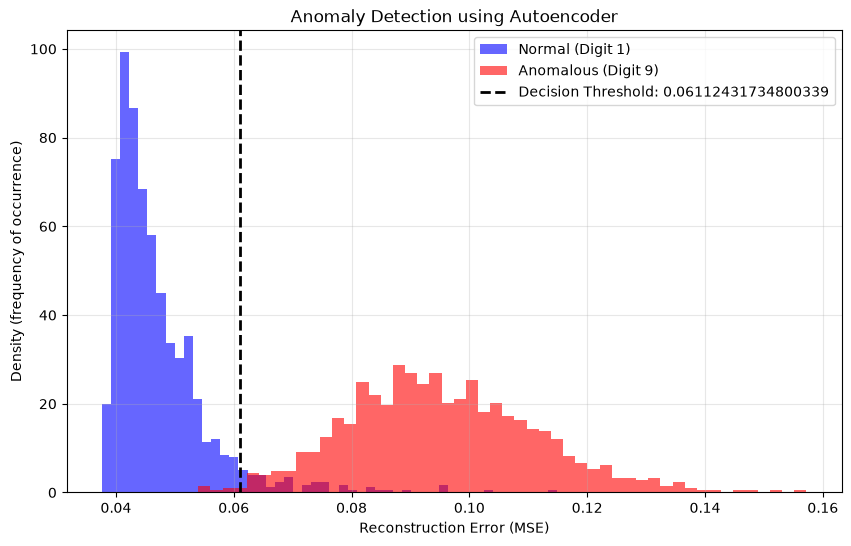

In [68]:
print("Computing reconstruction losses for 'normal' (digit '1') and 'anomalous' (digit '9') data")
losses_ones = compute_reconstruction_losses(model, test_ones_loader)
losses_nines = compute_reconstruction_losses(model, test_nines_loader)

plt.figure(figsize=(10, 6))

plt.hist(losses_ones, bins=50, alpha=0.6, label='Normal (Digit 1)', color='blue', density=True)
plt.hist(losses_nines, bins=50, alpha=0.6, label='Anomalous (Digit 9)', color='red', density=True)

THRESHOLD = np.percentile(losses_ones, 95)
plt.axvline(x=THRESHOLD, color='black', linestyle='dashed', linewidth=2, label=f'Decision Threshold: {THRESHOLD}')

plt.xlabel('Reconstruction Error (MSE)')
plt.ylabel('Density (frequency of occurrence)')
plt.title('Anomaly Detection using Autoencoder')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## Plot analysis

$\color{blue}{\text{Blue part}}$ - Digit 1 - MSE is around 0.04-0.05. Model knows digit 1 very well, so it reproduces it easily, getting low reconstruction error as a result

$\color{red}{\text{Red part}}$ - Digit 9 (anomaly) - MSE is around 0.08-0.09. Encoder dissapoints with digit 9 as an input, which results in considerably bigger error.

`Conclusion` - Two parts are definitely separated. Autoencoder learns properly and accurately distinguishes between normal digit from anomaly